# Binoculars and erecting prisms

A Keplerian telescope, an objective and an eyepiece of focal lengths
$f_\mathrm{o}$ and $f_\mathrm{e}$ a distance $f_\mathrm{o} + f_\mathrm{e}$
apart, is an **afocal** system: parallel light in, parallel light out, the
angles magnified by $M = -f_\mathrm{o}/f_\mathrm{e}$. The minus sign is the
problem: the image is upside down and reversed left to right (left
sketch), fine for the stars, useless for a bird. A binocular turns it
around with prisms, and there are two families:

- **Porro prisms** (middle): two right angle prisms with crossed sections,
  each reflecting twice by total internal reflection (TIR). The path is
  folded, which shortens the instrument, and the objectives sit further
  apart than the eyes, which exaggerates depth.
- **Roof prisms** (right): here the Schmidt–Pechan prism, a half-penta
  prism and a Schmidt prism with a roof, objective and eyepiece on one
  axis. Slim and straight, but the roof splits the beam into two halves
  with different polarization, which costs contrast unless the roof faces
  carry a **phase coating**.

This notebook follows both with `pyoptics.prisms` (prisms traced in 3D with
polarization ray tracing matrices, as in notebook
[406 (polarization ray tracing)](406_polarization_raytrace.ipynb)) and `pyoptics.eyepieces`
(notebook [432 (eyepieces)](432_eyepieces.ipynb)): the image orientation, the tunnel
diagrams that size the prisms, the prisms as a glass block in the lens
design, and the roof phase error with its cure.

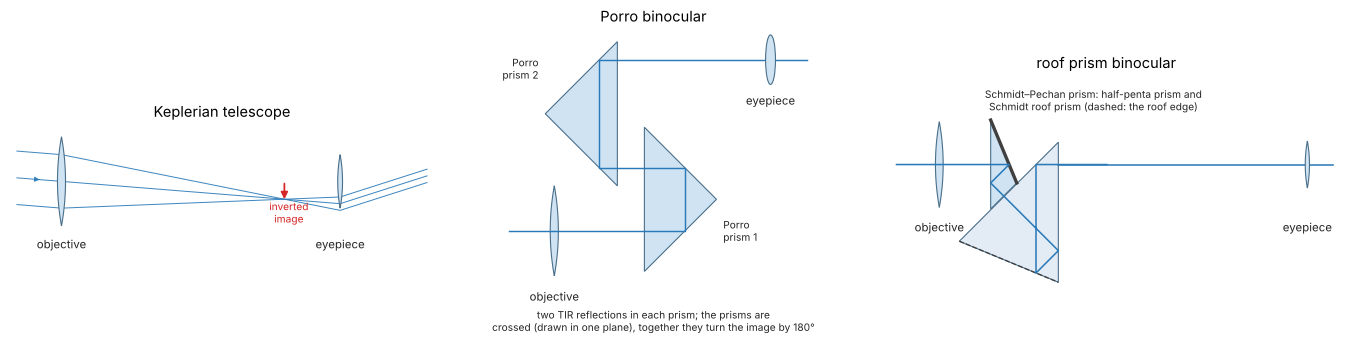

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import eyepieces as ep
from pyoptics import prisms as pr
from pyoptics import raytrace as rt
from pyoptics import glasses as gl
from pyoptics import lens_optimization as lo
from pyoptics import sketch
from pyoptics.coatings import Coating, Layer

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "0.45"
t_start = time.time()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw=dict(width_ratios=[1.0, 0.8, 1.1]))
with sketch.text_scale(1.15):
    sketch.binocular_layout(ax[0], "kepler", title="Keplerian telescope")
    sketch.binocular_layout(ax[1], "porro", title="Porro binocular")
    sketch.binocular_layout(ax[2], "roof", title="roof prism binocular")
plt.tight_layout(); plt.show()

## 1. Which way up: reflections as matrices

A plane mirror with the unit normal $\hat n$ maps a direction $\mathbf v$
to $H\mathbf v$ with the Householder matrix $H = I - 2\hat n\hat n^T$. A
prism is the product of its reflections, $O = H_k\cdots H_1$
(`pr.orientation()`, which collects the faces that a traced ray actually
meets). With input and output along $z$, the upper left $2\times2$ block of
$O$ tells what happens to the image, and $\det O = (-1)^k$ whether it is a
mirror image. The telescope itself contributes $-I$ (the image turned by
180°). The beam diameter is $D = 1$ for all prisms in this section; they
scale with it.

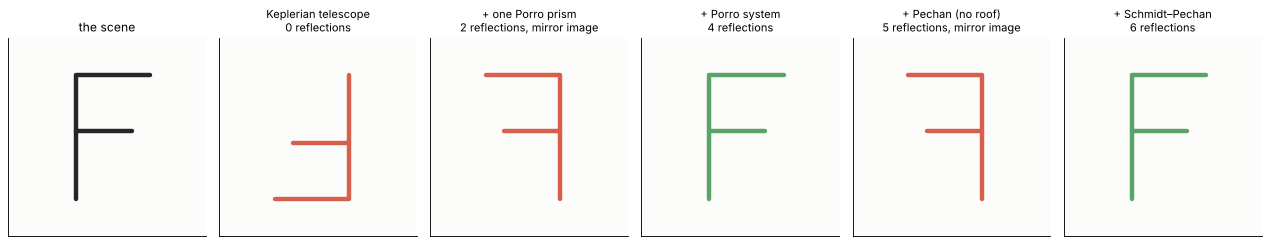

In [2]:
porro1 = pr.porro_prism(1.0)
porro = pr.porro_system(1.0)
sp = pr.schmidt_pechan(1.0)
pechan = pr.schmidt_pechan(1.0, roof=False)

cases = [("Keplerian telescope", None, None),
         ("+ one Porro prism", [porro1], ((0.01, -0.55, -5.0), (0.0, 0.0, 1.0))),
         ("+ Porro system", porro, ((0.01, 0.01, -5.0), (0.0, 0.0, 1.0))),
         ("+ Pechan (no roof)", pechan, ((0.01, 0.01, -5.0), (0.0, 0.0, 1.0))),
         ("+ Schmidt–Pechan", sp, ((0.01, 0.01, -5.0), (0.0, 0.0, 1.0)))]

F = np.array([[0, 0], [0, 1], [0.6, 1], [np.nan, np.nan], [0, 0.55], [0.45, 0.55]]) - [0.25, 0.5]
fig, axes = plt.subplots(1, 6, figsize=(16, 3.2))
axes[0].plot(F[:, 0], F[:, 1], color="0.15", lw=4, solid_capstyle="round")
axes[0].set_title("the scene", fontsize=11)
for (name, prisms, ray), ax in zip(cases, axes[1:]):
    T = -np.eye(2)
    n_refl = 0
    if prisms is not None:
        O, events = pr.orientation(prisms, ray=ray)
        n_refl = sum(e[2] in ("TIR", "mirror") for e in events)
        T = O[:2, :2] @ T
    G = F @ T.T
    mirror = np.linalg.det(T) < 0
    upright = (not mirror) and np.allclose(T, np.eye(2), atol=1e-9)
    ax.plot(G[:, 0], G[:, 1], color=GREEN if upright else RED, lw=4, solid_capstyle="round")
    ax.set_title("{}\n{} reflections{}".format(name, n_refl, ", mirror image" if mirror else ""),
                 fontsize=10)
for ax in axes:
    ax.set_xlim(-0.8, 0.8); ax.set_ylim(-0.8, 0.8); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

One Porro prism reverses one coordinate (two reflections in one plane fold
the beam back, a mirror image of the whole field); the second prism,
turned by 90° about the axis, reverses the other: together they turn the
image by 180° and the telescope's inversion is undone. The Schmidt–Pechan
prism does the same with six reflections: four in the principal section
and two on the roof faces, which exchange left and right across the
section. Without the roof (a plain Pechan prism, whose base is then a
mirror coated plane face) five reflections remain and the image is mirrored, which is fine for a rangefinder or a periscope, but
not for a binocular. The roof is not optional, and section 4 shows its
price.

## 2. Tunnel diagrams: how big must a prism be?

A reflection inside a prism can be unfolded by mirroring the prism at the
reflecting face: the ray continues straight into the mirrored copy. Doing
this for every reflection (`pr.unfold()`, drawn by `pr.draw_tunnel()`)
turns the prism into a *tunnel*: a beam passes the prism if it fits through
the tunnel, and the prism is optically a plane parallel block of glass of
the same length. Left: the principal sections with the axial ray and the
rim of a beam of diameter $D = 1$ (thick: the mirror coated face of the
half-penta prism, dashed: the roof); right: their tunnel diagrams.

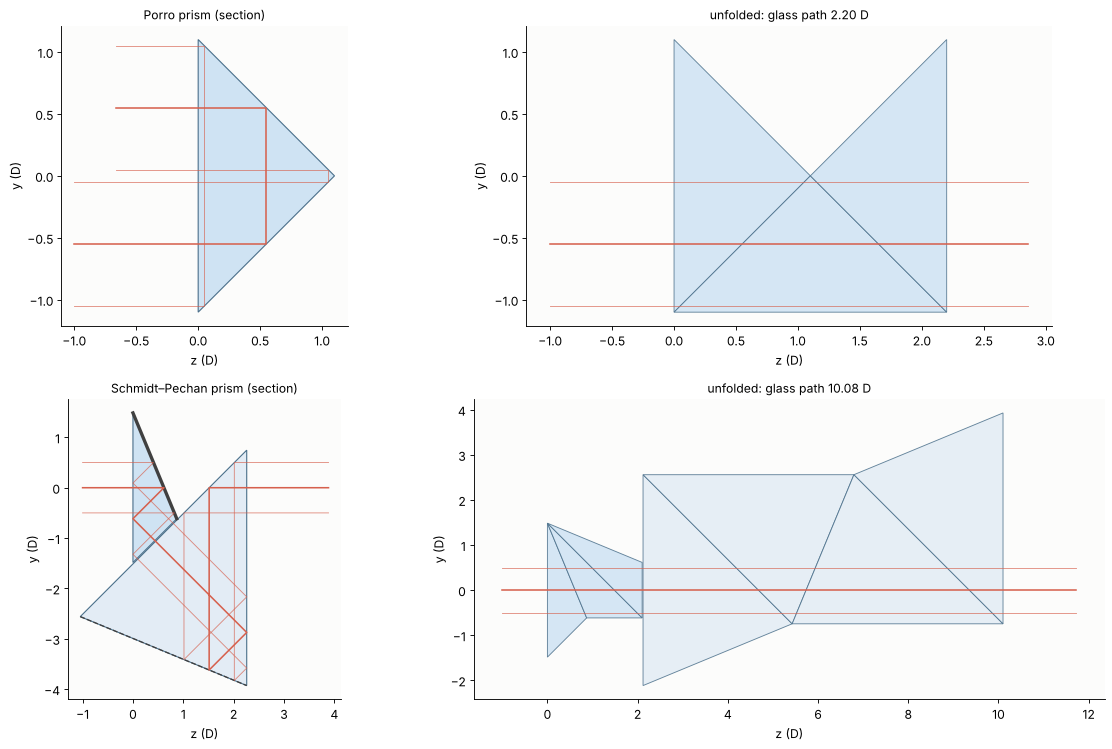

glass path, 3D trace of a ray near the axis: Porro system 4.40 D, Schmidt–Pechan 10.08 D


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5), gridspec_kw=dict(width_ratios=[1, 1.6]))
start_porro = (-1.0, -0.55)
pr.draw_section(axes[0, 0], [porro1], start_porro, beam=1.0)
L_porro = pr.draw_tunnel(axes[0, 1], [porro1], start_porro, beam=1.0)
pr.draw_section(axes[1, 0], sp, (-1.0, 0.0), beam=1.0)
L_sp = pr.draw_tunnel(axes[1, 1], sp, (-1.0, 0.0), beam=1.0)
axes[0, 0].set_title("Porro prism (section)", fontsize=11)
axes[0, 1].set_title("unfolded: glass path {:.2f} D".format(L_porro), fontsize=11)
axes[1, 0].set_title("Schmidt–Pechan prism (section)", fontsize=11)
axes[1, 1].set_title("unfolded: glass path {:.2f} D".format(L_sp), fontsize=11)
for ax in axes.ravel():
    ax.set_xlabel("z (D)"); ax.set_ylabel("y (D)")
plt.tight_layout(); plt.show()
print("glass path, 3D trace of a ray near the axis: Porro system {:.2f} D, Schmidt–Pechan {:.2f} D"
      .format(pr.glass_path(porro, ray=((0.01, 0.01, -5.0), (0.0, 0.0, 1.0))), pr.glass_path(sp)))

The Porro prism unfolds into a block as long as its hypotenuse: twice the
beam diameter plus the margin (10 % here), and the system of two prisms
into a block of 4.4 $D$. The Schmidt–Pechan prism of `pr.schmidt_pechan()`
is longer: its components here are cut generously, with the input and the
output beam on one axis, and its ten beam diameters of glass are folded
into a length of about three. The two pupil halves of the roof, which
appear as one face in the section, are the subject of section 4.

The tunnel diagram also shows why the prisms sit in the converging beam
behind the objective: there the beam is narrower and the prisms smaller,
but every ray then crosses a thick plane parallel plate at an angle, which
adds aberrations.

## 3. The prisms in the lens design: a glass block

For the sequential ray trace, the prisms are their tunnel: a plate of
N-BAK4. We build an 8×42 binocular: an achromatic objective of
$f_\mathrm{o} = 160$ mm (f/3.8), the Erfle eyepiece of notebook
[432 (eyepieces)](432_eyepieces.ipynb) scaled to $f_\mathrm{e} = 20$ mm (8×, 65° apparent, 8.1° real
field, exit pupil 5.25 mm), and a Porro system for the converging beam,
whose diameter is about 21 mm at the prisms: $L = 4.4 \times 21 \approx 92$ mm
of glass. The objective is optimized with damped least squares (notebook
[410 (lens optimization)](410_lens_optimization.ipynb)) for its own focus, once in air and once with the
block, and `ep.telescope()` puts the eyepiece behind it; `ep.afocal_blur()`
measures the angular blur leaving the eyepiece (F, d, C, the eye
accommodating), in arcminutes as the eye sees it.

objective radii (mm): in air [100.3, -60.1, -216.1], with the prisms [108.5, -60.1, -189.9]


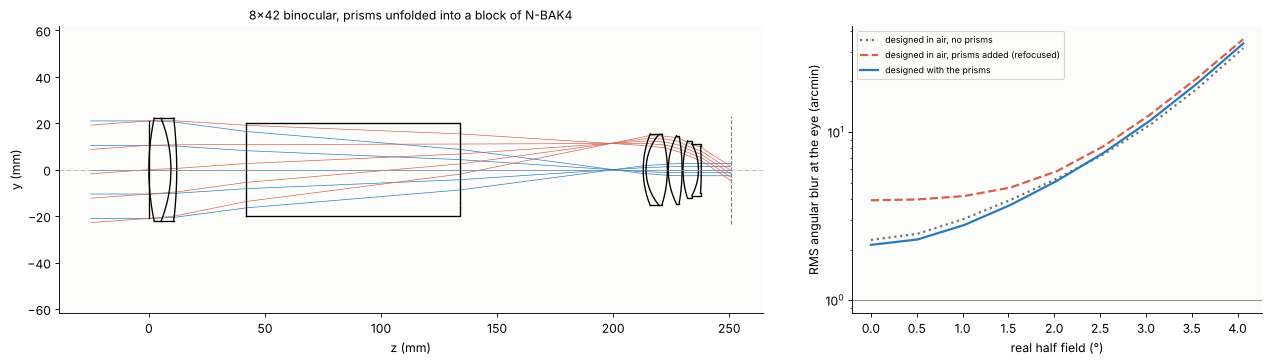

In [4]:
WL = ep.WAVELENGTHS
BK7, F2, BAK4 = gl.get("N-BK7"), gl.get("N-F2"), gl.get("N-BAK4")
f_o, D_obj, L_block = 160.0, 42.0, 92.0
erfle = ep.erfle(20.0)


def objective(R, block=0.0):
    S = [rt.Surface(np.inf, 0.0, semi_diameter=D_obj/2, label="objective (stop)"),
         rt.Surface(R[0], 9.5, material=BK7), rt.Surface(R[1], 2.5, material=F2),
         rt.Surface(R[2], 30.0 if block else 100.0, n_after=1.0)]
    if block:
        S += [rt.Surface(np.inf, block, material=BAK4, label="prisms"),
              rt.Surface(np.inf, 30.0, n_after=1.0)]
    s = rt.System(S, 0, WL["d"], field_angle=np.radians(4.06))
    lo.solve_paraxial_focus()(s)
    return s


def optimize(s):
    ops = [lo.polychromatic_ray_errors(list(WL.values()), fields=(0.0, 0.7, 1.0), tolerance=0.002)]
    cons = [lo.Constraint(lo.paraxial_value("efl"), f_o, f_o, tolerance=1e-3, name="efl")]
    return lo.DampedLeastSquares(s, lo.curvatures(s, [1, 2, 3]), ops, cons,
                                 [lo.solve_paraxial_focus()]).run(max_iterations=60).system


R_start = [100.0, -70.0, -300.0]
in_air = optimize(objective(R_start))
R_air = [in_air.surfaces[i].R for i in (1, 2, 3)]
with_block = optimize(objective(R_air, L_block))
R_block = [with_block.surfaces[i].R for i in (1, 2, 3)]

designs = {"designed in air, no prisms": objective(R_air),
           "designed in air, prisms added (refocused)": objective(R_air, L_block),
           "designed with the prisms": objective(R_block, L_block)}
binoculars = {k: ep.telescope(erfle, f_o, objective=s.surfaces) for k, s in designs.items()}
print("objective radii (mm): in air {}, with the prisms {}".format(
    np.round(R_air, 1).tolist(), np.round(R_block, 1).tolist()))

fig = plt.figure(figsize=(16, 4.6))
ax0 = fig.add_axes([0.04, 0.12, 0.55, 0.78])
b = binoculars["designed with the prisms"]
b.draw(ax0, fields=[0.0, b.max_field], n_rays=5, colors=[BLUE, RED], lw=0.6)
ax0.set_title("8×42 binocular, prisms unfolded into a block of N-BAK4", fontsize=11)
ax0.set_xlabel("z (mm)"); ax0.set_ylabel("y (mm)")
ax1 = fig.add_axes([0.66, 0.12, 0.32, 0.78])
fields = np.linspace(0, np.degrees(b.max_field), 9)
for (name, tel), c, ls in zip(binoculars.items(), (GREY, RED, BLUE), (":", "--", "-")):
    ax1.plot(fields, ep.afocal_blur(tel, fields), ls, color=c, lw=2, label=name)
ax1.axhline(1.0, color=GREY, lw=0.7)
ax1.set_yscale("log"); ax1.set_xlabel("real half field (°)")
ax1.set_ylabel("RMS angular blur at the eye (arcmin)")
ax1.legend(fontsize=8, loc="upper left")
plt.show()

Ninety millimetres of glass in a converging f/3.8 beam are a large
aberration: the objective that is fine in air (dotted) blurs the centre
of the field to about 4 arcmin once the prisms are added (dashed), mostly
spherical aberration and axial colour of the plate, which the eyepiece
magnifies eightfold. Designed *with* the block (solid), the same three
radii bring the centre back to the 2 arcmin of the objective in air (the
secondary spectrum of a simple achromat, magnified 8×: a quarter
arcminute in the object space); beyond about 2° the field is limited by
the eyepiece. This is why binocular objectives are always
designed together with their prisms, and why the prism glass (N-BAK4,
or the cheaper N-BK7, whose lower index costs a vignetted pupil through
TIR failure in Porro prisms) is part of the prescription.

## 4. The roof phase error

The roof of the Schmidt–Pechan prism reflects every ray twice, once on
each roof face. Rays in the half of the beam at $x > 0$ meet the faces in
the order (+, −), those at $x < 0$ in the order (−, +). Both halves are
turned by the same rotation, but the s and p directions of the two TIRs
differ between the halves, and TIR shifts the phases of p and s by
different amounts: 50° apart at the 49° angle of incidence on the roof
faces of N-BAK4 (`pr.tir_retardance()` gives 130°, the same retardance in
the sign convention of `thin_films`, where $r_p$ carries an extra
factor −1). `pr.jones_pupil()` traces a collimated beam
through the prism and returns the Jones matrix of every ray, with the
Fresnel losses of the entrance and exit faces, the coated mirror face B
and all TIR phases:

Schmidt–Pechan, bare roof: retardance between the halves 141°
Porro system: 0.0°


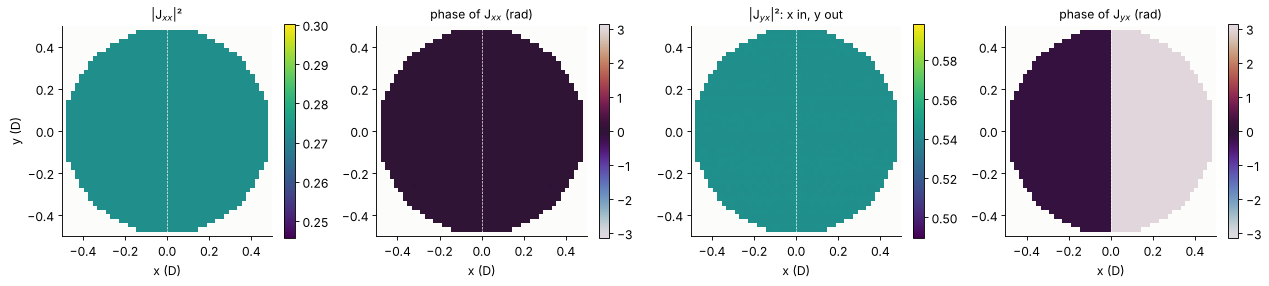

In [5]:
x, y, J_sp = pr.jones_pupil(sp, 1.0, n=48)
xp, yp, J_porro = pr.jones_pupil(porro, 1.0, n=48, z_start=-5.0)
phase, retard = pr.roof_error(J_sp, x)
print("Schmidt–Pechan, bare roof: retardance between the halves {:.0f}°".format(np.degrees(retard)))
print("Porro system: {:.1f}°".format(np.degrees(pr.roof_error(J_porro, xp)[1])))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
ext = [-0.5, 0.5, -0.5, 0.5]
panels = [(np.abs(J_sp[..., 0, 0])**2, "|J$_{xx}$|²", "viridis", None),
          (np.angle(J_sp[..., 0, 0]/J_sp[24, 24, 0, 0]), "phase of J$_{xx}$ (rad)", "twilight",
           (-np.pi, np.pi)),
          (np.abs(J_sp[..., 1, 0])**2, "|J$_{yx}$|²: x in, y out", "viridis", None),
          (np.angle(J_sp[..., 1, 0]), "phase of J$_{yx}$ (rad)", "twilight", (-np.pi, np.pi))]
for ax, (val, title, cmap, lim) in zip(axes, panels):
    im = ax.imshow(val, extent=ext, origin="lower", cmap=cmap,
                   vmin=None if lim is None else lim[0], vmax=None if lim is None else lim[1])
    ax.axvline(0, color="w", lw=0.6, ls="--")
    ax.set_title(title, fontsize=11); ax.set_xlabel("x (D)")
    plt.colorbar(im, ax=ax, fraction=0.046)
axes[0].set_ylabel("y (D)")
plt.tight_layout(); plt.show()

The bare Schmidt–Pechan prism is a strong retarder: x polarized light
leaves with a large y component. The two halves of the pupil (left and
right of the dashed roof edge) transmit the same powers, but the cross
polarized component $J_{yx}$ changes its sign across the roof edge (a
phase jump of $\pi$), and with it the polarization state of the light
leaving the two halves differs by a retardance of 141°. Light of the two
halves no longer interferes completely in the focus. The Porro prisms,
whose four reflections all lie in planes that contain the axis, have
no such split.

What the eye sees: the point spread function in the focus of a perfect
lens behind the prism (`pr.polarized_psf()`, unpolarized light, normalized
so that its peak is the Strehl ratio), the image of a star. The maps show
the square root of the intensity, to make the faint rings visible:

phase coating, layers from the glass outwards (n, thickness in nm): [(2.35, 26.7), (1.46, 138.5), (2.35, 46.6), (1.46, 1.0)]
remaining retardance per roof reflection at 450, 550, 650 nm: [10.1, -11.1, 7.0] degrees


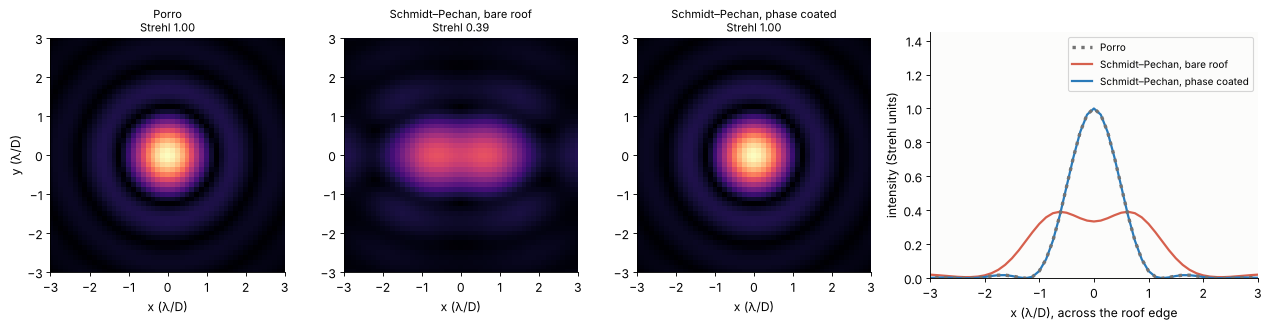

In [6]:
from scipy.optimize import least_squares

coating, retard_left = pr.phase_coating()
sp_coated = pr.schmidt_pechan(1.0, roof_coating=coating)
xc, yc, J_coated = pr.jones_pupil(sp_coated, 1.0, n=48)
print("phase coating, layers from the glass outwards (n, thickness in nm):",
      [(l.material, float(round(l.thickness*1e6, 1))) for l in coating.layers])
print("remaining retardance per roof reflection at 450, 550, 650 nm: {} degrees".format(
    np.round(np.degrees(retard_left), 1).tolist()))

psfs = {"Porro": pr.polarized_psf(J_porro), "Schmidt–Pechan, bare roof": pr.polarized_psf(J_sp),
        "Schmidt–Pechan, phase coated": pr.polarized_psf(J_coated)}
pad, n = 8, 48
N = pad*n
u = (np.arange(N) - N//2)/pad  # in units of lambda/D
fig, axes = plt.subplots(1, 4, figsize=(16, 4.0), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.4]))
for ax, (name, I) in zip(axes, psfs.items()):
    ax.imshow(np.sqrt(I), extent=[u[0], u[-1], u[0], u[-1]], origin="lower", cmap="magma",
              vmin=0, vmax=1)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
    ax.set_title("{}\nStrehl {:.2f}".format(name, I.max()), fontsize=10)
    ax.set_xlabel("x (λ/D)")
axes[0].set_ylabel("y (λ/D)")
for (name, I), c in zip(psfs.items(), (GREY, RED, BLUE)):
    axes[3].plot(u, I[N//2], color=c, lw=2 if c != GREY else 3,
                 ls=":" if c == GREY else "-", label=name, zorder=3 if c == GREY else 2)
axes[3].set_xlim(-3, 3); axes[3].set_xlabel("x (λ/D), across the roof edge")
axes[3].set_ylabel("intensity (Strehl units)"); axes[3].legend(fontsize=9, loc="upper right"); axes[3].set_ylim(0, 1.45)
plt.tight_layout(); plt.show()

With the bare roof the Airy disc collapses to a Strehl ratio of about
0.4: the cross polarized light of the two halves interferes destructively
on the axis and forms two side lobes across the roof edge, the classic
image of an uncoated roof prism binocular (a star with flanks, softer
contrast at fine detail). The phase coating, four layers of a high and a
low index material (TiO$_2$-like and SiO$_2$-like) under the TIR on each
roof face found by `pr.phase_coating()`, makes the s and p phases of each
roof reflection nearly equal, and the PSF returns to that of the Porro
prisms. (Its fourth layer came out nearly zero: three layers do the work.)
Real phase coatings, introduced by Carl Zeiss in the late 1980s, use
dozens of layers to hold this over the whole visible spectrum
and the range of angles of a converging beam.

How well does it hold over the spectrum? The Strehl ratio from 430 to 680 nm:

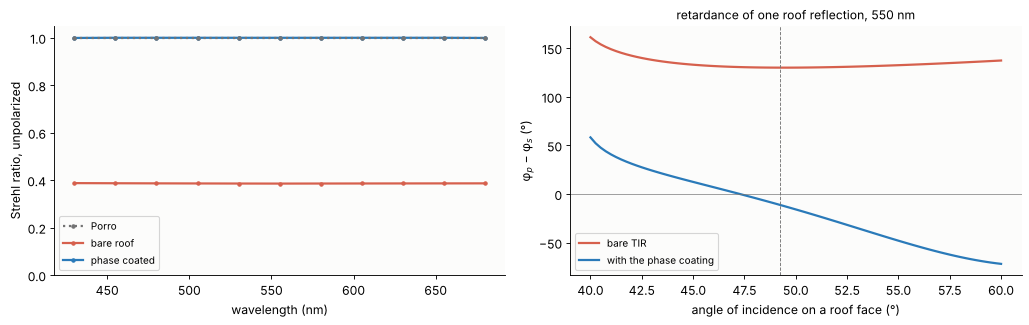

In [7]:
wls = np.linspace(430e-6, 680e-6, 11)
strehl = {k: [] for k in ("Porro", "bare roof", "phase coated")}
for w in wls:
    for name, prisms, z0 in (("Porro", porro, -5.0), ("bare roof", sp, -1.0),
                             ("phase coated", sp_coated, -1.0)):
        _, _, J = pr.jones_pupil(prisms, 1.0, wavelength=w, n=32, z_start=z0)
        strehl[name].append(pr.polarized_psf(J, pad=4).max())

ang = np.radians(np.linspace(40, 60, 81))
n_bak4 = BAK4(550.0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for (name, s_), c in zip(strehl.items(), (GREY, RED, BLUE)):
    ax[0].plot(wls*1e6, s_, "o:" if c == GREY else "o-", ms=3, color=c, lw=2, label=name,
               zorder=3 if c == GREY else 2)
ax[0].set_xlabel("wavelength (nm)"); ax[0].set_ylabel("Strehl ratio, unpolarized")
ax[0].set_ylim(0, 1.05); ax[0].legend(fontsize=9)
ax[1].plot(np.degrees(ang), np.degrees(pr.tir_retardance(n_bak4, ang)), color=RED, lw=2,
           label="bare TIR")
ret = []
for a in ang:
    r_s, r_p = coating.amplitudes(np.array([np.cos(a)]), n_bak4, 1.0, 550e-6, 550.0)[:2]
    ret.append(np.degrees(np.angle(r_p[0]/r_s[0])))
ax[1].plot(np.degrees(ang), ret, color=BLUE, lw=2, label="with the phase coating")
roof_angle = np.degrees(np.arccos(np.cos(np.radians(22.5))*np.sqrt(0.5)))
ax[1].axvline(roof_angle, color=GREY, lw=0.8, ls="--")
ax[1].axhline(0, color=GREY, lw=0.6)
ax[1].set_xlabel("angle of incidence on a roof face (°)"); ax[1].set_ylabel("φ$_p$ − φ$_s$ (°)")
ax[1].set_title("retardance of one roof reflection, 550 nm", fontsize=11); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

The four-layer coating keeps the Strehl ratio above 0.99 across the
visible spectrum, where the bare roof stays at 0.39. For the Strehl ratio
only the difference between the two halves counts, and the residual
retardance of the coating is nearly the same for both. On the
right: the retardance of a single roof reflection against the angle of
incidence. In a converging beam (f/3.8 behind the objective) the angles
on the roof faces spread by several degrees, and the coating, designed for one
angle, keeps the retardance within a few tens of degrees there; a real
coating is designed for this spread too.

## 5. The coated face and the light budget

One reflection of the Schmidt–Pechan prism, on face B of the half-penta
prism at 22.5°, is below the critical angle and needs a mirror coating.
Aluminium reflects about 90 %, silver about 97 %, dielectric stacks more
than 99 %. `pr.trace()` gives the transmitted power of every ray from its
polarization matrix; we compare the two prism systems with bare and
anti-reflection coated (a quarter wave of MgF$_2$) entrance and exit
faces. The optical constants of the metals are approximate values for
evaporated films (aluminium after Rakić, silver after Johnson and
Christy), interpolated in wavelength:

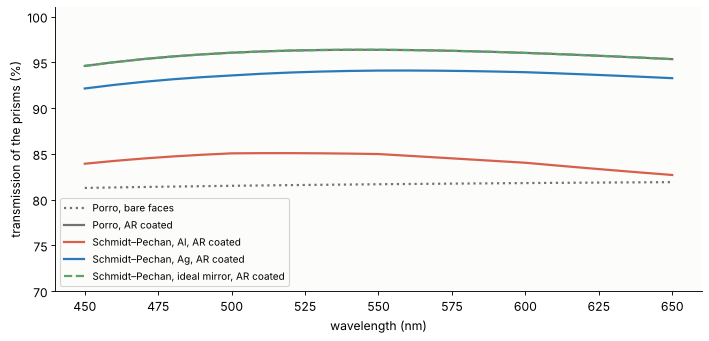

In [8]:
metal = {"aluminium": ([450, 500, 550, 600, 650], [0.62 + 5.47j, 0.77 + 6.08j, 0.96 + 6.69j,
                                                    1.20 + 7.26j, 1.49 + 7.82j]),
         "silver": ([450, 500, 550, 600, 650], [0.04 + 2.66j, 0.05 + 3.09j, 0.055 + 3.47j,
                                                0.06 + 3.81j, 0.07 + 4.18j])}


def metal_index(name):
    wl, nk = metal[name]
    return lambda w: np.interp(w, wl, np.real(nk)) + 1j*np.interp(w, wl, np.imag(nk))


ar = Coating([Layer.quarter_wave(1.38, 550e-6)])


def transmission(prisms, wavelength, z0):
    tr = pr.trace(prisms, [[0.01, 0.01, z0]], [[0.0, 0.0, 1.0]], wavelength)
    P = tr.P[0]
    return 0.5*(np.sum(np.abs(P[:, 0])**2) + np.sum(np.abs(P[:, 1])**2))


wls = np.linspace(450e-6, 650e-6, 21)
variants = {
    "Porro, bare faces": ([pr.porro_system(1.0)], -5.0, GREY, ":"),
    "Porro, AR coated": ([pr.porro_system(1.0)], -5.0, GREY, "-"),
    "Schmidt–Pechan, Al, AR coated": ([pr.schmidt_pechan(
        1.0, mirror_coating=Coating((), substrate=metal_index("aluminium")), ar_coating=ar,
        roof_coating=coating)], -1.0, RED, "-"),
    "Schmidt–Pechan, Ag, AR coated": ([pr.schmidt_pechan(
        1.0, mirror_coating=Coating((), substrate=metal_index("silver")), ar_coating=ar,
        roof_coating=coating)], -1.0, BLUE, "-"),
    "Schmidt–Pechan, ideal mirror, AR coated": ([pr.schmidt_pechan(
        1.0, ar_coating=ar, roof_coating=coating)], -1.0, GREEN, "--")}
# the AR coated Porro system
for p_ in variants["Porro, AR coated"][0][0]:
    for f in p_.faces:
        if f.label == "hypotenuse":
            f.coating = ar
fig, ax = plt.subplots(figsize=(9, 4.4))
for name, (prisms, z0, c, ls) in variants.items():
    T = [transmission(prisms[0], w, z0) for w in wls]
    ax.plot(wls*1e6, 100*np.array(T), ls, color=c, lw=2, label=name)
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("transmission of the prisms (%)")
ax.legend(fontsize=9); ax.set_ylim(70, 101)
plt.tight_layout(); plt.show()

With bare faces a Porro system loses about 5 % at each of its four glass
surfaces; a single MgF$_2$ layer brings that to about 1.5 % per surface.
The Schmidt–Pechan prism has the same four surfaces, but its faces A, E
and X both transmit and reflect by TIR, and the aluminium mirror alone
costs another 11 %: an aluminized roof prism binocular is darker than
a Porro binocular of the same aperture. Silver and dielectric mirrors (and
multilayer AR coatings) close most of the gap, which is why both are
standard in good roof prism binoculars today. The AR layer on the faces
that also reflect by TIR does not hurt: TIR stays total through a thin
layer as long as its index does not let the light out.

## Summary

- A Keplerian telescope inverts the image; reflections are Householder
  matrices, and the erecting prism must contribute a 180° rotation
  without a mirror image (`pr.orientation()`): two crossed Porro prisms,
  or the six reflections of a Schmidt–Pechan prism with its roof.
- Tunnel diagrams (`pr.unfold()`, `pr.draw_tunnel()`) size the prisms and
  turn them into plane parallel blocks for the sequential trace (`pr.glass_path()`).
- The block adds spherical aberration and colour that the objective must
  correct: binocular objectives are designed with their prisms.
- The roof splits the pupil into two halves of different polarization:
  a bare Schmidt–Pechan prism halves the Strehl ratio, a phase coating on
  the roof faces (`pr.phase_coating()`) restores it.
- The one coated reflection of the Schmidt–Pechan prism costs light; silver
  or dielectric mirrors and AR coated faces bring it close to a Porro
  system.

## References

- W. J. Smith, *Modern Optical Engineering*, 4th ed., McGraw-Hill (2008),
  chapter 8 (prisms, tunnel diagrams).
- R. A. Chipman, W.-S. T. Lam and G. Young, *Polarized Light and Optical
  Systems*, CRC Press (2018).
- A. D. Rakić, "Algorithm for the determination of intrinsic optical
  constants of metal films", Appl. Opt. 34, 4755–4767 (1995).
- P. B. Johnson and R. W. Christy, "Optical constants of the noble
  metals", Phys. Rev. B 6, 4370–4379 (1972).

In [9]:
print("run time {:.0f} s".format(time.time() - t_start))

run time 10 s
